# When the parcel is late, the stars fall
A short walk through the business story using the DuckDB marts built by `src/run_pipeline.py`.
**Question:** how strongly are late deliveries associated with worse reviews, and who or where are they concentrated?

**Limitations up front:** observational data (association, not causation); 84% of late-order reviews were written before the parcel arrived; 646 delivered orders have no review and reviewers self-select; multi-seller orders (1.3%) share one lateness flag.

In [1]:
import sys
from pathlib import Path
from IPython.display import Image, display
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
from src.olist import build
con = build()  # rebuilds data/olist.duckdb from data/raw (about 5 s)
q = lambda sql: con.execute(sql).fetchdf()
IMG, FIGS = ROOT.parent / "images", ROOT / "figures"  # README charts / extra charts
q("SELECT COUNT(*) AS orders, ROUND(SUM(gmv)) AS gmv_brl, MIN(purchased_at) AS first, MAX(purchased_at) AS last FROM fct_orders")

,orders,gmv_brl,first,last
0,99441,13591644.0,2016-09-04 21:15:19,2018-10-17 17:30:18


## 1. The data, and the grain traps
`fct_orders` has exactly one row per order. Items are aggregated *before* joining payments and reviews, so revenue isn't double-counted:

In [2]:
q("""SELECT (SELECT SUM(gmv) FROM fct_orders) AS fct_gmv,
          (SELECT SUM(price) FROM stg_order_items) AS item_gmv,
          (SELECT COUNT(*) FROM (SELECT order_id FROM raw_reviews GROUP BY 1 HAVING COUNT(*) > 1)) AS orders_with_multiple_reviews,
          (SELECT COUNT(*) FROM (SELECT review_id FROM raw_reviews GROUP BY 1 HAVING COUNT(DISTINCT order_id) > 1)) AS review_ids_shared_across_orders""")

,fct_gmv,item_gmv,orders_with_multiple_reviews,review_ids_shared_across_orders
0,13591643.7,13591643.7,547,789


## 2. Primary comparison: reviews written after delivery
Olist sends the survey around the estimated date, so most late-order reviews are written before the parcel arrives. The fair comparison is late vs on time **among reviews written after delivery**.

,delivery,review_timing,orders,pct_of_group,avg_score,pct_1_2_star
0,late,after delivery,1049,16.44,3.779,18.30
1,late,before delivery,5332,83.56,1.974,71.10
2,on time,after delivery,86635,96.86,4.291,9.25
3,on time,before delivery,2808,3.14,4.276,9.76


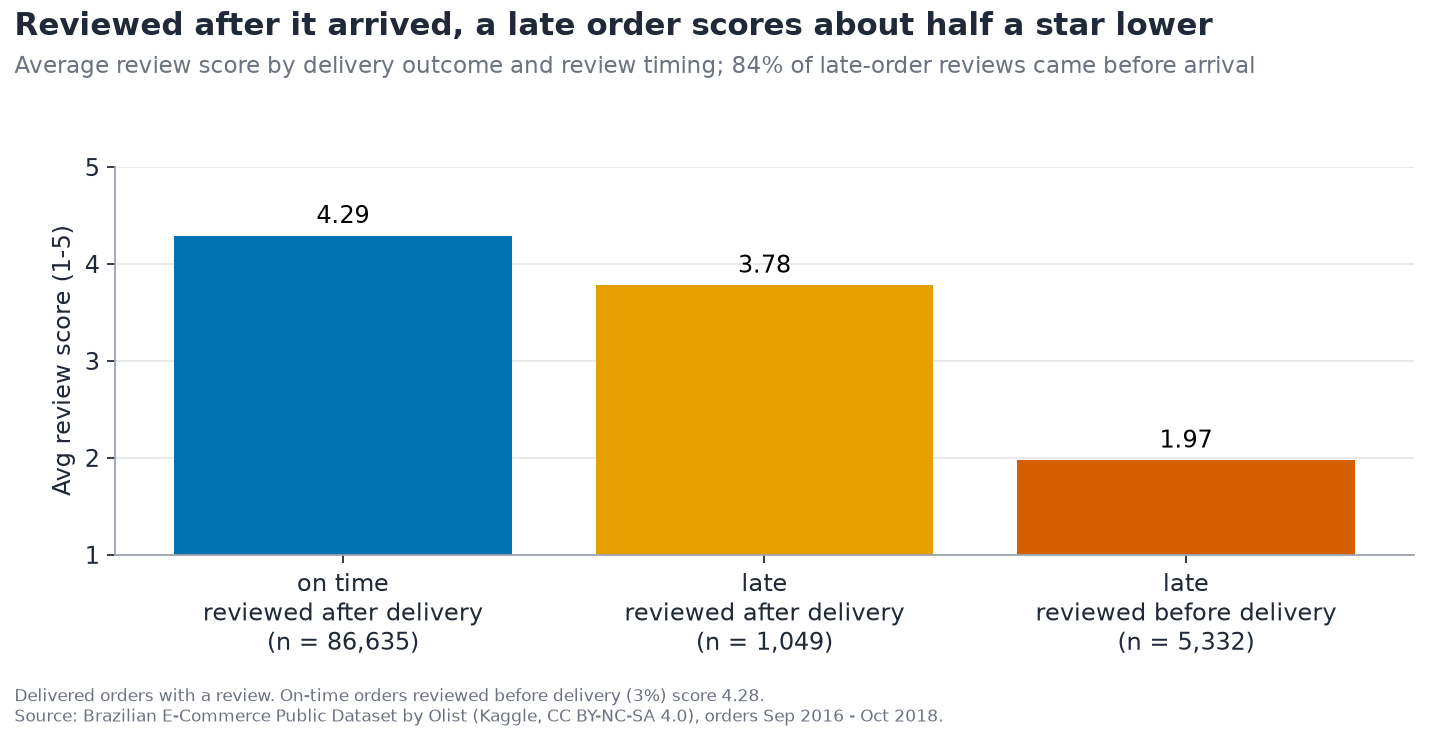

In [3]:
display(q("SELECT * FROM mart_late_vs_ontime_by_timing")); display(Image(IMG / "08_review_timing.png"))

In [4]:
import sys; sys.path.insert(0, str(ROOT / "src"))
from run_pipeline import headline_metrics
m = headline_metrics(con)
print(f"PRIMARY  after delivery: {m['late_after_delivery_score']:.2f} vs {m['ontime_after_delivery_score']:.2f}, gap {m['gap_after_delivery']:+.2f} "
      f"(Welch 95% CI {m['gap_after_t_ci']}, bootstrap {m['gap_after_boot_ci']}); stratified {m['gap_after_stratified_state_items']:+.2f}")
print(f"SECONDARY before delivery: {m['pct_late_reviews_before_delivery']:.0f}% of late reviews, {m['late_before_delivery_score']:.2f} stars, gap {m['gap_before_delivery']:+.2f}")
print(f"Pooled: gap {m['gap_all']:+.2f} (CI {m['gap_all_t_ci']}); stratified by state and item count {m['gap_stratified_state_items']:+.2f}")

PRIMARY  after delivery: 3.78 vs 4.29, gap -0.51 (Welch 95% CI [-0.595, -0.429], bootstrap [-0.596, -0.436]); stratified -0.55
SECONDARY before delivery: 84% of late reviews, 1.97 stars, gap -2.32
Pooled: gap -2.02 (CI [-2.059, -1.981]); stratified by state and item count -2.03


## 3. All reviews pooled, by days late ('on estimate day' counts as on time)

In [5]:
q("SELECT * FROM mart_late_vs_ontime")

,delivery,orders,avg_score,pct_1_2_star
0,late,6381,2.27,62.42
1,on time,89443,4.29,9.27


,late_bucket,orders,pct_of_orders,avg_score,pct_1_2_star,pct_5_star
0,1. early,88163,92.01,4.294,9.22,62.44
1,2. on estimate day (on time),1280,1.34,4.034,12.42,50.63
2,3. 1-3 days late,1852,1.93,3.291,32.13,33.15
3,4. 4-7 days late,1748,1.82,2.103,67.68,14.07
4,5. 8-14 days late,1446,1.51,1.671,80.15,6.85
5,6. 15+ days late,1335,1.39,1.724,78.35,7.19


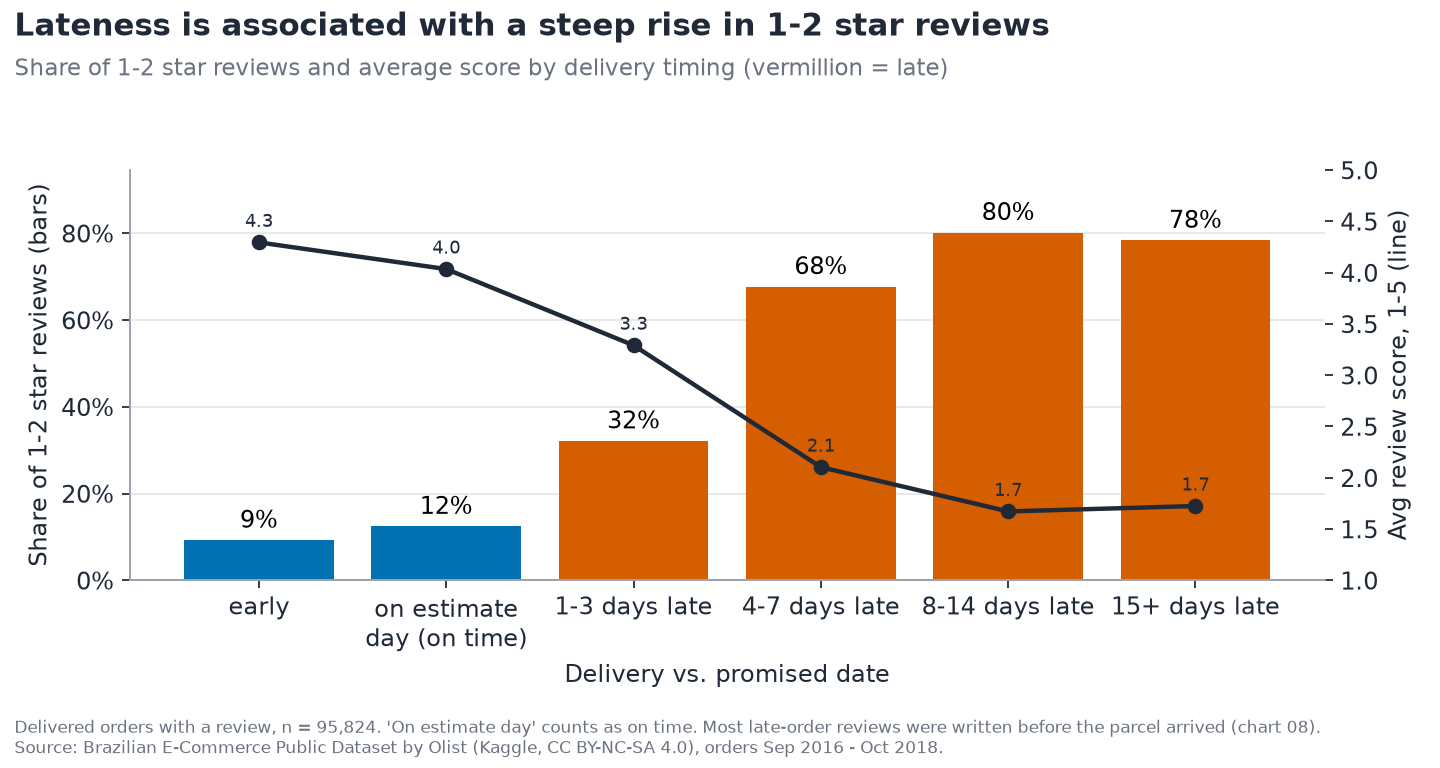

In [6]:
display(q("SELECT * FROM mart_delivery_vs_reviews")); display(Image(IMG / "01_late_vs_reviews.png"))

## 4. Promises are padded, yet still missed

In [7]:
q("SELECT * FROM mart_estimate_accuracy")

,delivered_orders,avg_promised_days,avg_actual_days,median_days_early,late_rate_pct
0,96470,24.4,12.5,12.0,6.77


## 5. Sellers, out of sample
Ranked on 2017 late rate (shrunk toward the mean), measured on 2018 orders. Ranking and reporting on the same data would be circular.

,late_quartile,sellers,orders_2018,ranked_late_2017_pct,late_rate_pct,avg_score,pct_sp_sellers
0,1,46,4027.0,2.97,6.85,4.129,56.5
1,2,46,7204.0,4.34,6.75,4.138,54.3
2,3,46,5382.0,5.74,8.36,4.087,80.4
3,4,46,8490.0,8.74,9.60,3.980,89.1


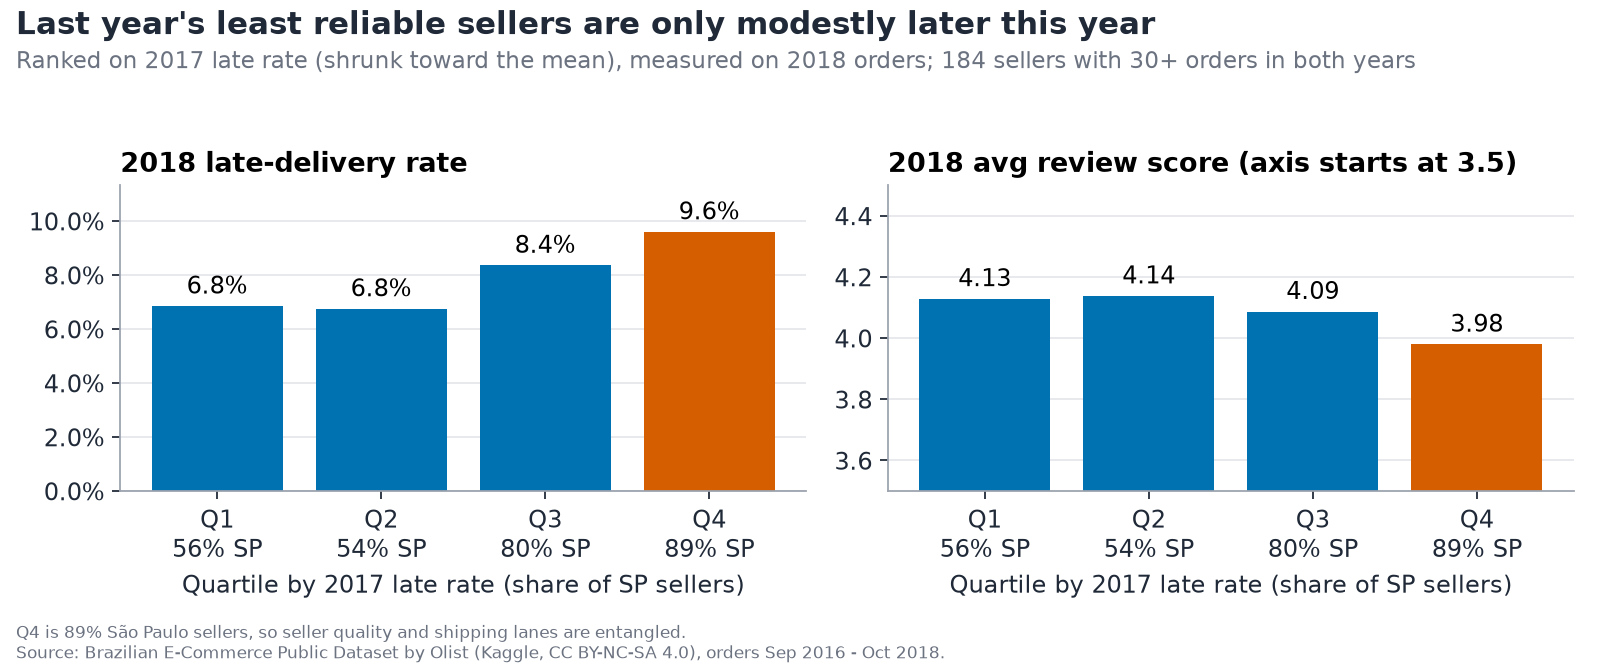

In [8]:
display(q("SELECT * FROM mart_seller_tiers")); display(Image(IMG / "02_seller_tiers.png"))

In [9]:
q("SELECT * FROM mart_worst_sellers")

,seller_id,seller_state,orders,late_rate_pct,avg_score,late_rank
0,ede0c03645598cdfc63ca8237acbe73d,SP,43,32.6,3.57,1
1,ad781527c93d00d89a11eecd9dcad7c1,SP,38,31.6,3.34,2
2,54965bbe3e4f07ae045b90b0b8541f52,PR,73,30.1,3.14,3
3,2a1348e9addc1af5aaa619b1a3679d6b,MG,48,27.1,3.17,4
4,835f0f7810c76831d6c7d24c7a646d4d,SP,42,26.2,3.36,5
5,beadbee30901a7f61d031b6b686095ad,SP,64,23.4,3.91,6
6,a49928bcdf77c55c6d6e05e09a9b4ca5,SP,96,21.9,3.03,7
7,ef990a83bbea832f36ebe81376335aa8,SC,43,20.9,3.63,8
8,712e6ed8aa4aa1fa65dab41fed5737e4,SC,77,20.8,3.39,9
9,3fd1e727ba94cfe122d165e176ce7967,SP,35,20.0,3.94,10


## 6. Where? States and lanes
São Paulo sellers shipping to the North-East (AL, MA, SE, PI) are the worst lanes.

,seller_state,customer_state,orders,late_rate_pct,median_delivery_days,avg_score
0,SP,AL,254,24.02,23.0,3.706
1,MA,SP,123,20.33,14.0,3.926
2,SP,MA,486,19.14,20.0,3.720
3,SP,SE,205,16.59,18.0,3.839
4,SP,PI,327,16.51,17.0,3.969
5,PR,BA,143,14.69,18.0,3.823
6,SP,RJ,8048,14.25,13.0,3.903
7,SP,CE,961,13.84,18.0,3.973
8,SP,BA,2278,13.04,18.0,3.890
9,SP,MS,471,12.53,14.0,4.098


SP->AL Wilson 95% CI (%): [19.2, 29.6]


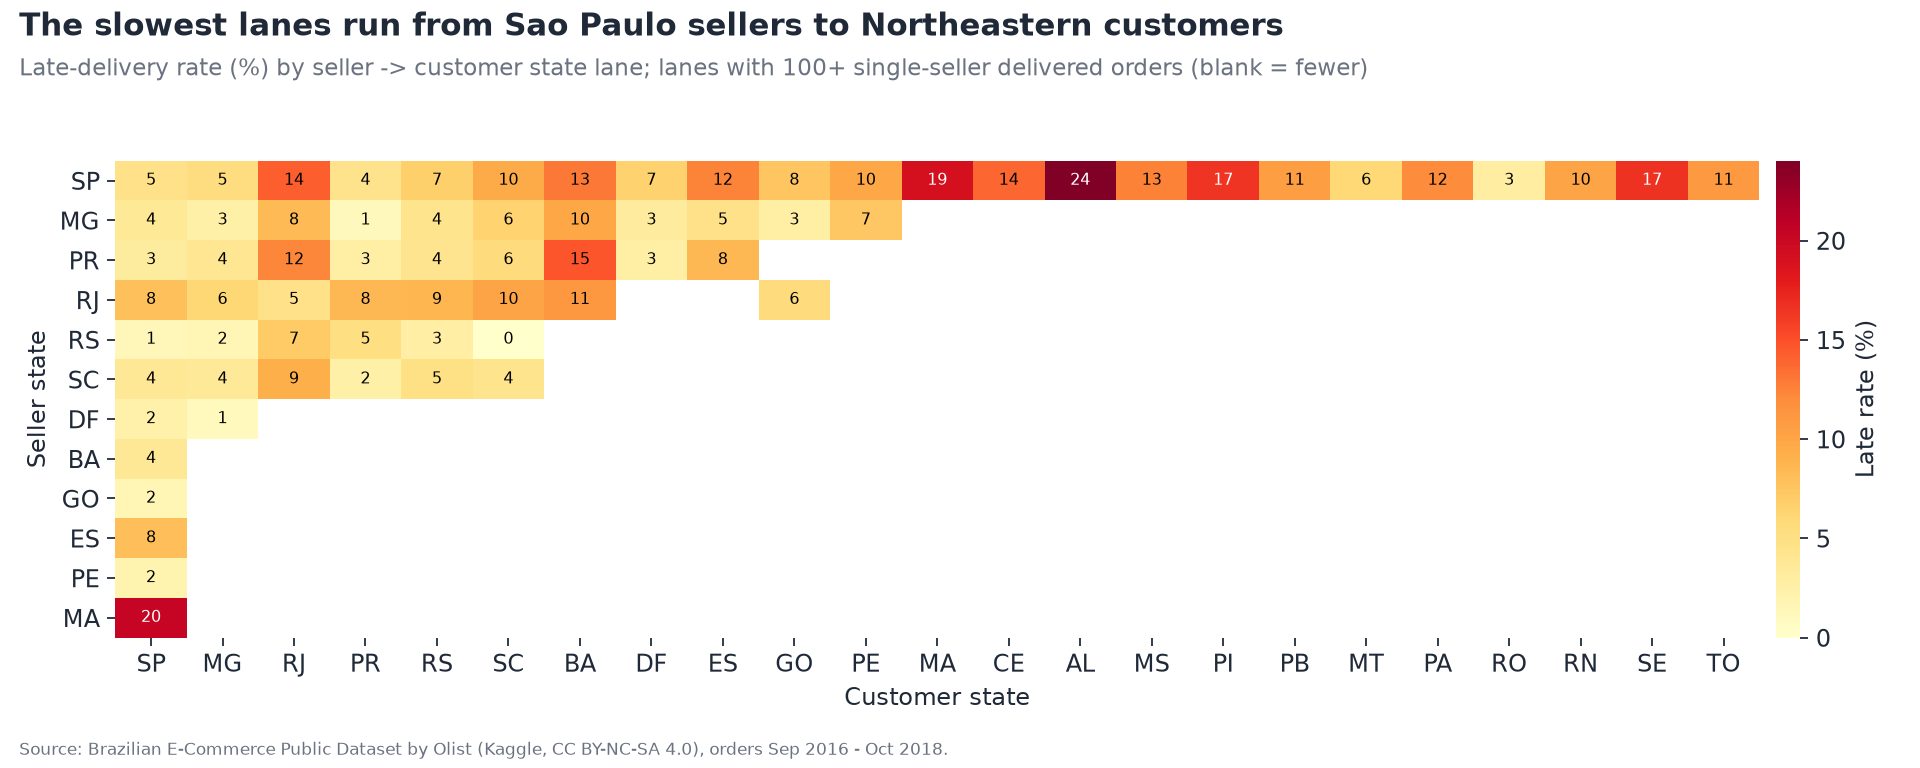

In [10]:
display(q("SELECT * FROM mart_lanes LIMIT 10")); print("SP->AL Wilson 95% CI (%):", m["worst_lane_wilson_ci_pct"]); display(Image(IMG / "06_lane_heatmap.png"))

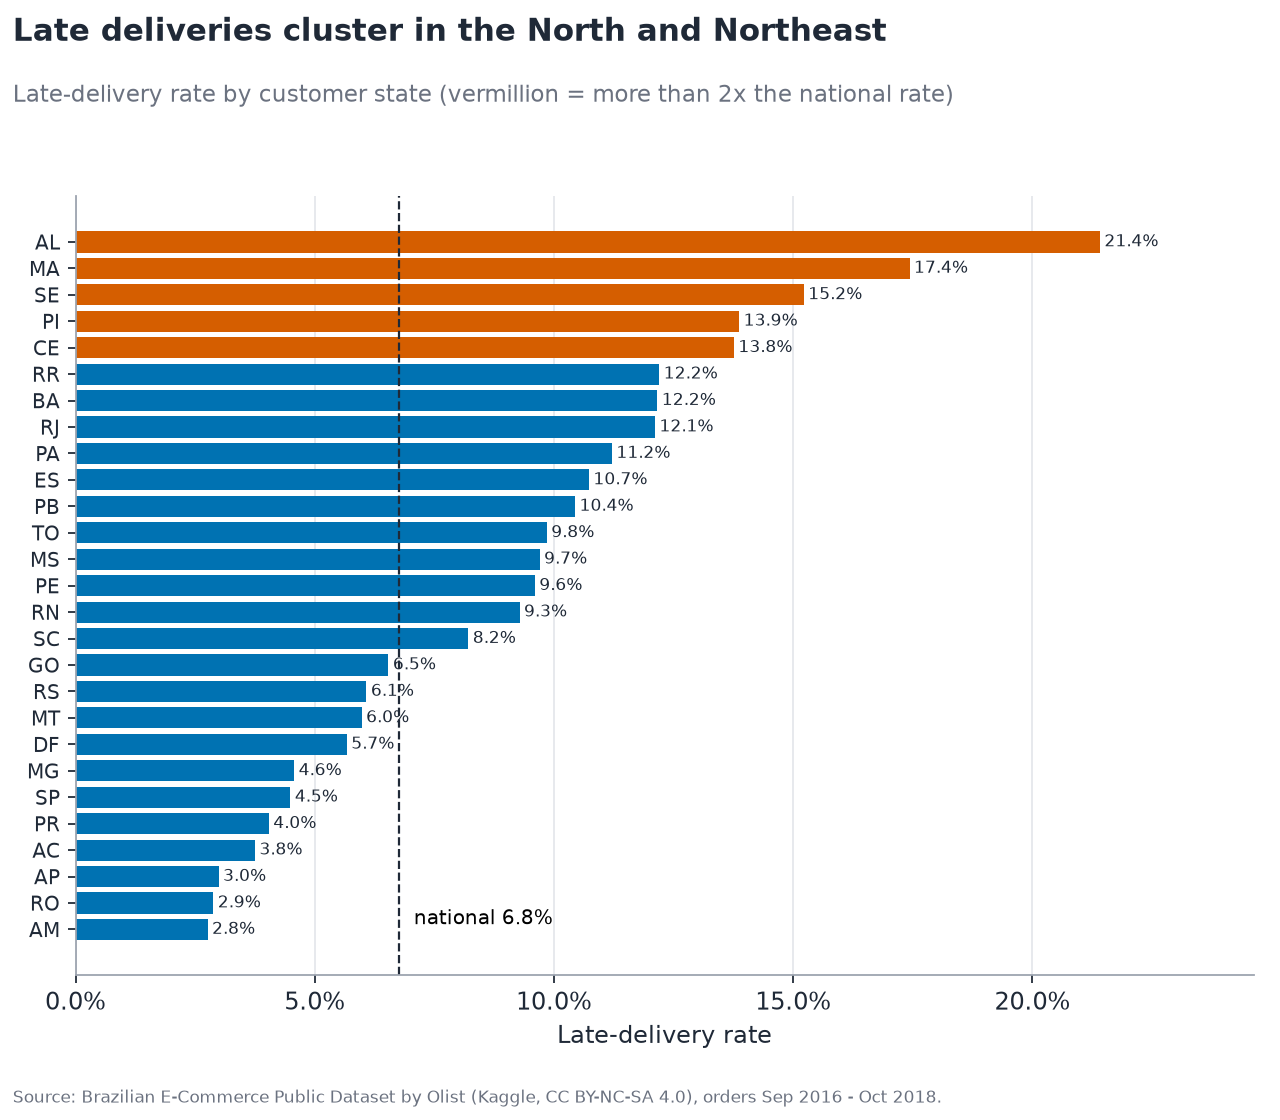

In [11]:
display(Image(FIGS / "04_state_late_rate.png"))

## 7. Categories

,category,orders,gmv,aov,late_rate_pct,avg_score,gmv_rank
0,health_beauty,8836,1258681.34,142.45,7.51,4.181,1
1,watches_gifts,5624,1205005.68,214.26,7.39,4.065,2
2,bed_bath_table,9417,1036988.68,110.12,7.43,3.971,3
3,sports_leisure,7720,988048.97,127.99,6.57,4.167,4
4,computers_accessories,6689,911954.32,136.34,6.39,4.026,5
5,furniture_decor,6449,729762.49,113.16,7.12,4.009,6
6,cool_stuff,3632,635290.85,174.91,5.90,4.170,7
7,housewares,5884,632248.66,107.45,5.36,4.141,8
8,auto,3897,592720.11,152.10,7.30,4.089,9
9,garden_tools,3518,485256.46,137.94,6.53,4.136,10


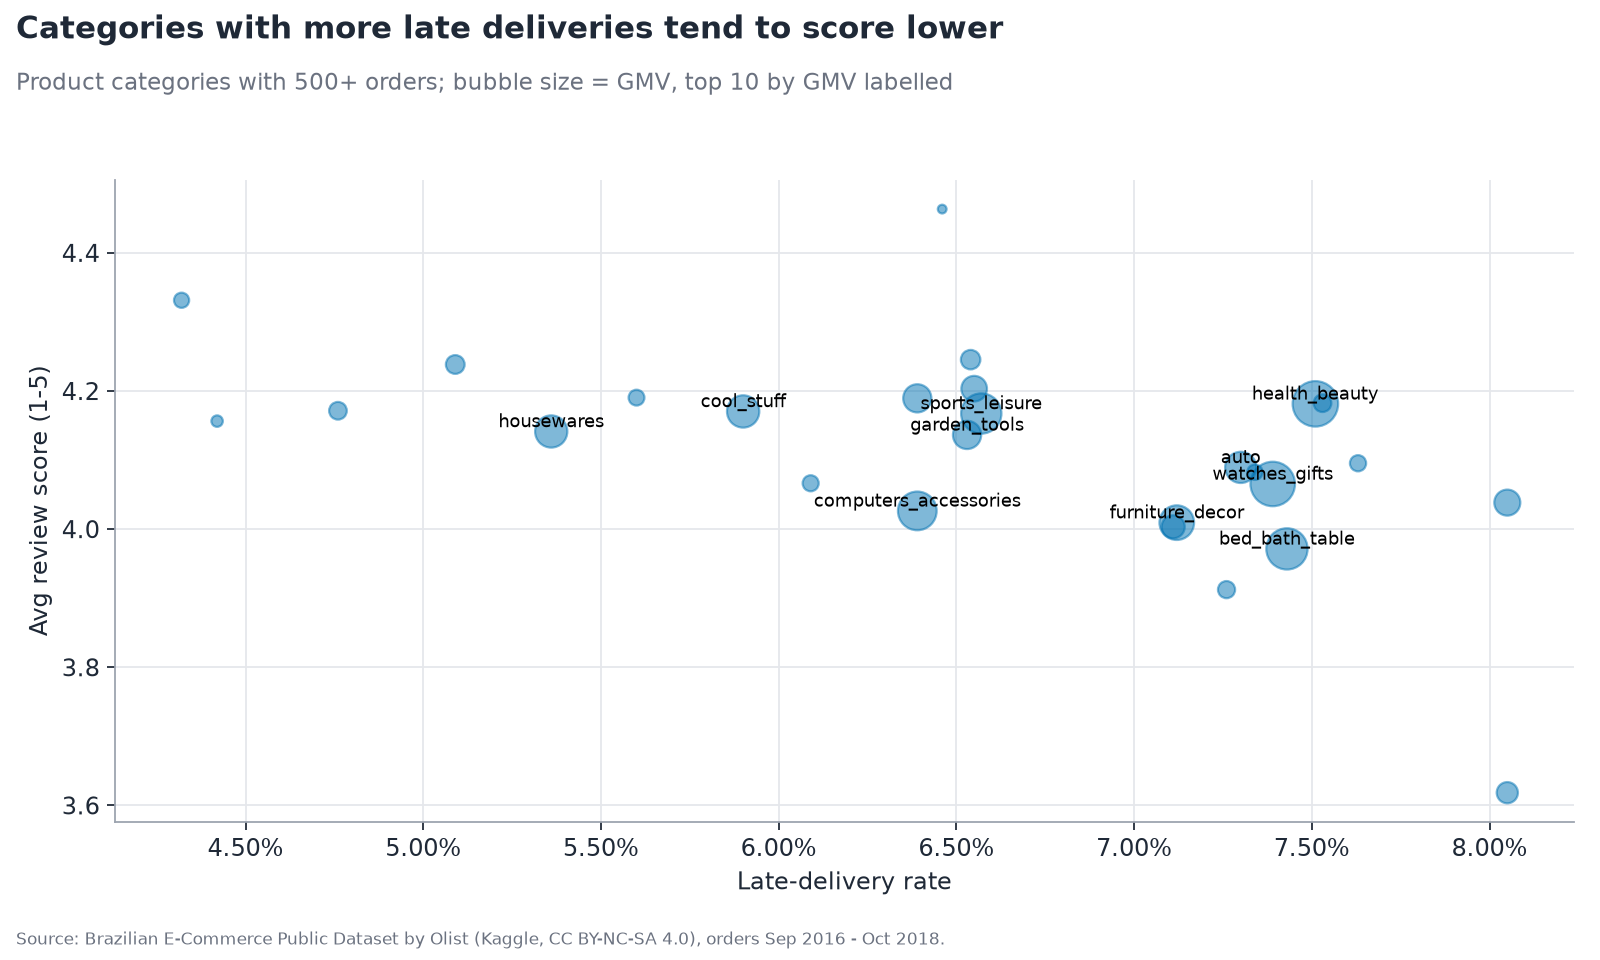

In [12]:
display(q("SELECT * FROM mart_categories LIMIT 10")); display(Image(FIGS / "05_category_matrix.png"))

## 8. Growth is strong, but retention is near zero

,customers,repeat_customers,repeat_rate_pct
0,94990,2888.0,3.04


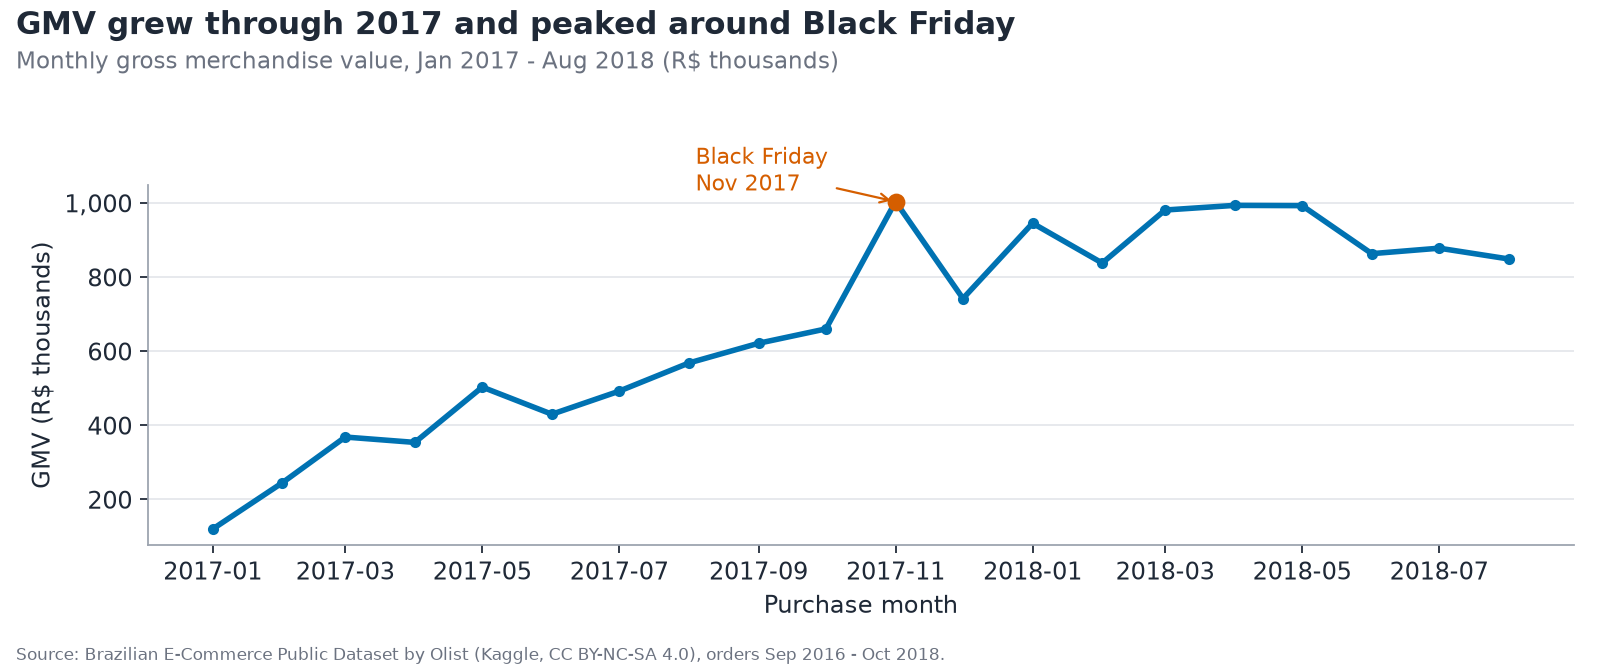

In [13]:
display(q("SELECT * FROM mart_repeat_customers")); display(Image(FIGS / "03_monthly_gmv.png"))

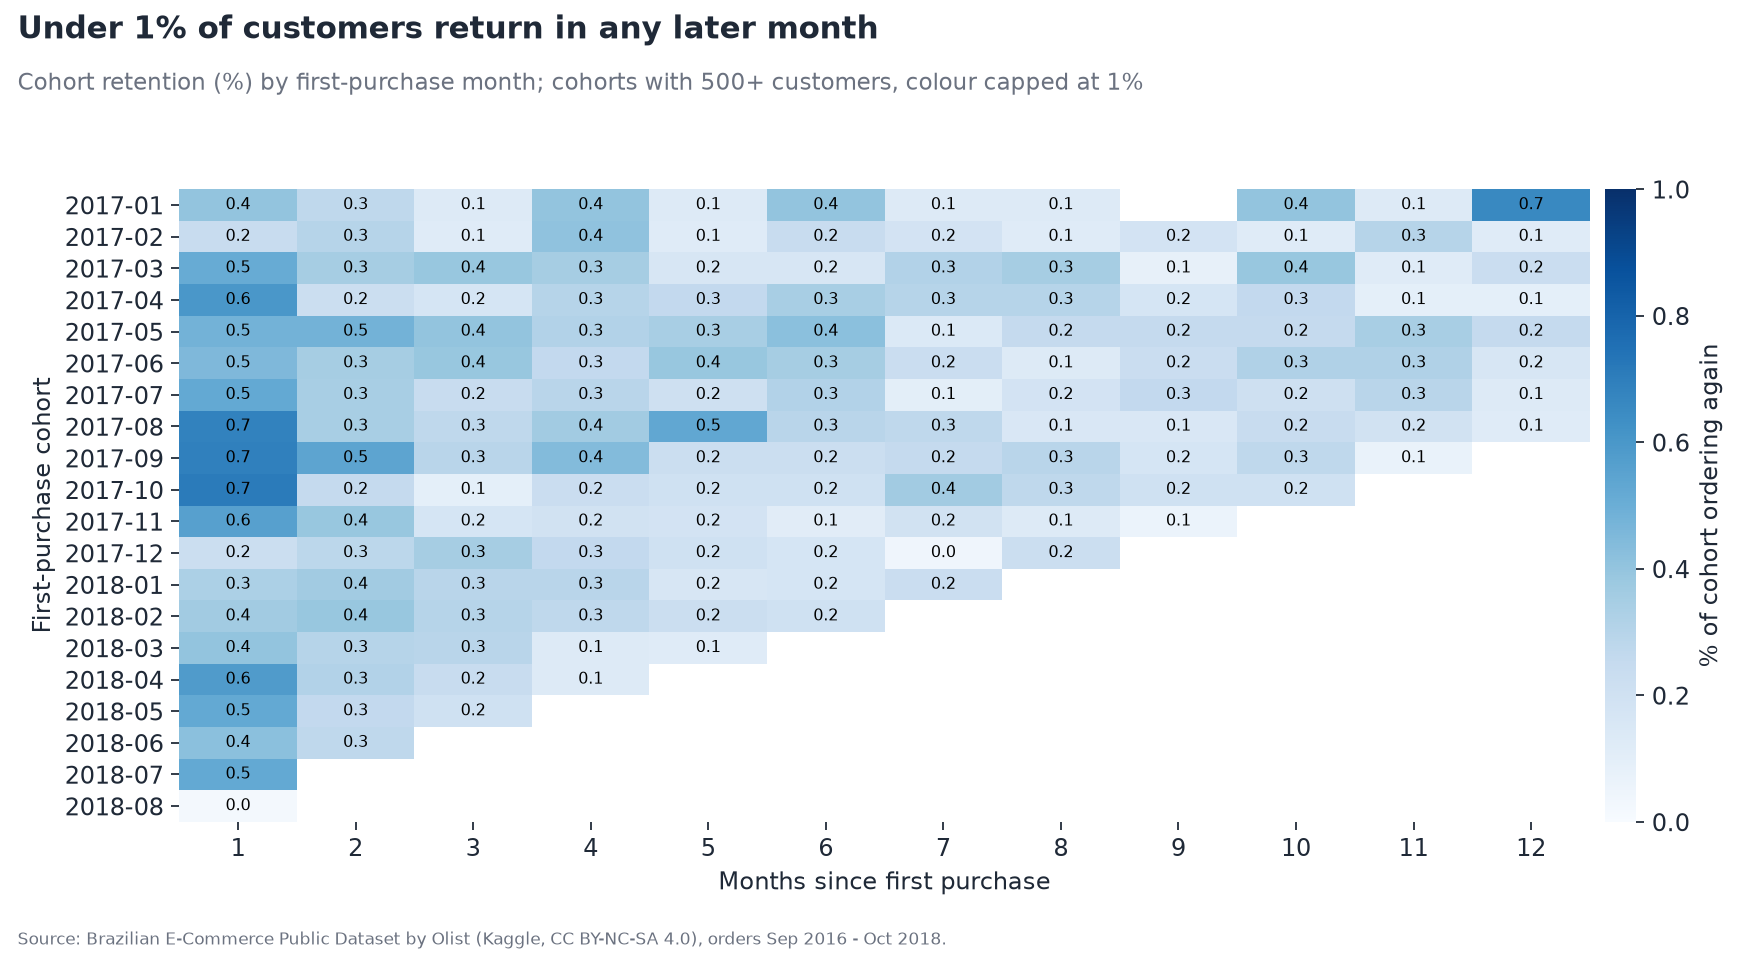

In [14]:
display(Image(FIGS / "07_cohort_retention.png"))

## 9. Payments

In [15]:
display(q("SELECT * FROM mart_payments")); display(q("SELECT * FROM mart_installments"))

,payment_type,orders,pct_orders,avg_order_value,avg_installments
0,credit_card,74975,75.40,167.29,3.55
1,boleto,19784,19.90,145.03,1.00
2,voucher,3151,3.17,120.29,1.14
3,debit_card,1527,1.54,142.72,1.00
4,not_defined,3,0.00,0.00,1.00


,installment_band,orders,avg_order_value
0,1 (single),24005,100.91
1,2-3,22649,135.58
2,4-6,16160,182.56
3,7+,12161,337.08


## Takeaways
1. Reviewed after delivery, late orders score **3.78★ vs 4.29★** on time (gap −0.51★, 95% CI −0.60 to −0.43).
2. **84%** of late-order reviews are written before the parcel arrives and average **1.97★**, so not having the order yet goes hand in hand with 1★ reviews.
3. Out of sample, 2017's least reliable seller quartile is only about **1.4x** as late in 2018 (9.6% vs 6.9%), and it is 89% São Paulo sellers: lanes matter as much as sellers.
4. SP → North-East lanes miss their estimates 15–24% of the time (SP→AL 24%, 95% CI 19–30%), even though estimates are padded by about 12 days.
5. Only **3%** of customers buy twice, so fixing first deliveries is also a retention play.

*Observational data: lateness is associated with worse reviews; this doesn't prove causation.*